# **LAB 03 - DNN shrinking & quantization**

**Credits**: *Călin Diaconu, Francesco Conti, Ilenia Carboni, Davide Nadalini, Lorenzo Lamberti, Luca Bompani, Alberto Dequino*.
*(University of Bologna)*

**Contacts**: calin.diaconu2@unibo.it, seyedahmad.mirsalar2@unibo.it, ihor.sachok@unibo.it, marco.labarbera2@unibo.it

## **Introduction**

In this session, we will learn how to quantize a CNN and how to visualize its graph.

### Tasks:

0. Set up the environment.
1. Load a model’s pretrained weights.
2. Reduce the network’s size under 5M MAC.
3. Re-train the reduced network and verify its accuracy.
4. Quantize the reduced network: fake-quantize it with Brevitas (post-training quantization and quantization-aware training), then true-quantize it with DeepQuant.
5. Export the float32 and true-quantized models to ONNX and analyze them with Netron.

## **Task 0:** Setup (only once)

Run the setup cell below **once**. It:
1. Installs PyTorch 2.6 for CPU (you don't need a GPU to run this lab, each network takes ~7 min to train).
2. Installs the other dependencies (Brevitas and a few helper libraries).
3. Installs DeepQuant (this takes a bit of time).
4. **Restarts the runtime automatically**, so that the newly installed packages are loaded.

Colab may then show a message saying that your session crashed or restarted: this is expected. If Colab asks you to restart the session while the cell is still running, ignore it and let the cell finish.

The restart keeps the installed packages and your files. Do **not** use *Disconnect and delete runtime*, or you will have to redo the whole setup.

We first need to setup the environment to a lower PyTorch version. We will setup PyTorch with no CUDA support. The neural networks won't take more than 7 mins to train!

Why CPU? DeepQuant needs an older PyTorch (2.6, the oldest version available for the Python 3.13 used by Colab), whose CPU-only build is much lighter to install than the CUDA one; the network is small enough to train quickly on CPU; and the rest of the lab (DeepQuant, sanity checks) assumes all tensors live on the CPU. Use a CPU runtime (*Runtime → Change runtime type → CPU*): a GPU runtime would only waste your GPU quota.

In [ ]:
# 1. CPU-only PyTorch (oldest version with Python 3.13 wheels, as used by Colab)
!pip uninstall -y torch torchvision torchaudio sympy
!pip install torch==2.6.0 torchvision==0.21.0 torchaudio==2.6.0 --index-url https://download.pytorch.org/whl/cpu

# 2. Other dependencies
!pip install tqdm scikit-learn brevitas torchinfo onnxscript

# 3. DeepQuant
!rm -rf DeepQuant/
!git clone --branch unitn25-exercise --single-branch https://github.com/FrancescoConti/DeepQuant.git
!cd DeepQuant && git submodule update --init --recursive && pip install -e .

# 4. SymPy compatible with torch.fx (last, so nothing upgrades it afterwards)
!pip install sympy==1.13.1

# 5. Restart the runtime to load the new packages
import os
os.kill(os.getpid(), 9)

**After running the previous cell, it is normal to get a warning message from Colab!**

### From now on, don't run the setup cell again. Let's move to the lab!

First, check that the setup worked:

In [ ]:
# Check that the setup worked (run after the restart)
from importlib.metadata import version
import torch

assert torch.__version__.startswith("2.6"), f"Expected PyTorch 2.6, found {torch.__version__}: re-run the setup cell"
assert version("sympy") == "1.13.1", f"Expected SymPy 1.13.1, found {version('sympy')}: re-run the setup cell"

try:
    from DeepQuant import brevitasToTrueQuant
except ImportError:
    from DeepQuant.DeepQuant import brevitasToTrueQuant

print("PyTorch", torch.__version__, "| Brevitas", version("brevitas"), "| SymPy", version("sympy"), "| DeepQuant OK")

We import most of the packages we need

In [ ]:
#basic
import os
from os.path import join
import time
from copy import deepcopy

#plotting
import matplotlib.pyplot as plt

#torch
import torch; print('\nPyTorch version in use:', torch.__version__, '\ncuda avail: ', torch.cuda.is_available())
import torch.nn as nn

#torchvision
from torchvision import transforms, datasets

# others
from tqdm.autonotebook import tqdm

# Brevitas
import brevitas.nn as qnn


Set device: between "cuda" and "cpu". You only have "cpu" available, by design.

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device: %s' % device)

---

### **Recap from LAB 02:**
This section recaps the previous lab. Take this as a chance to go over it again if something is not clear.

**This recap is optional.** Run all of its cells anyway, since they define functions used later in the lab, but you can skip the training run (it takes ~7 min): Task 1 loads pre-trained weights.

#### Creating a Model

Let's go back to our network from LAB2:

In [ ]:
class ConvBnRelu(nn.Module):
    def __init__(self, in_channels, out_channels, stride):
        super(ConvBnRelu, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False,
            padding_mode='zeros')
        
        self.bn1 = nn.BatchNorm2d(
            num_features=out_channels,
            eps=1e-05,
            momentum=0.1,
            affine=True,
            track_running_stats=True)
        
        self.relu1 = nn.ReLU()

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)

        return x

class CNN(nn.Module):
    def __init__(self, n_classes=10, depth_mult=1.):
        super(CNN, self).__init__()
        # first_conv_channels=int(32*depth_mult)
        self.ConvBnRelu1 = ConvBnRelu(1, 32, stride=1) # conv3x3: ch_in=1, ch_out=32, in=28x28, out=28x28
        self.ConvBnRelu2 = ConvBnRelu(32, 64, stride=1) # conv3x3: ch_in=32, ch_out=64, in=28x28, out=28x28

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
            padding=0,
            dilation=1,
            return_indices=False,
            ceil_mode=False) # MaxPool2: in=28x28, out=14x14
        
        self.ConvBnRelu3 = ConvBnRelu(64, 128, stride=2) # conv3x3 (stride 2): ch_in=64, ch_out=128, in=14x14, out=7x7
        self.dropout = nn.Dropout(p=0.5, inplace=False)

        fc_in_size = 7 * 7 * 128
        self.fc = nn.Linear(fc_in_size, n_classes, bias=False)
        # self.softmax = nn.LogSoftmax(dim=1) # we remove it: nn.CrossEntropyLoss already applies LogSoftmax internally, and argmax works directly on the logits

    def forward(self, x):
        x = self.ConvBnRelu1(x)
        x = self.ConvBnRelu2(x)
        x = self.pool(x)
        x = self.ConvBnRelu3(x)
        x = self.dropout(x)
        x = x.flatten(1)

        output = self.fc(x)
        # output = self.softmax(x)
        
        return output

net = CNN().to(device)


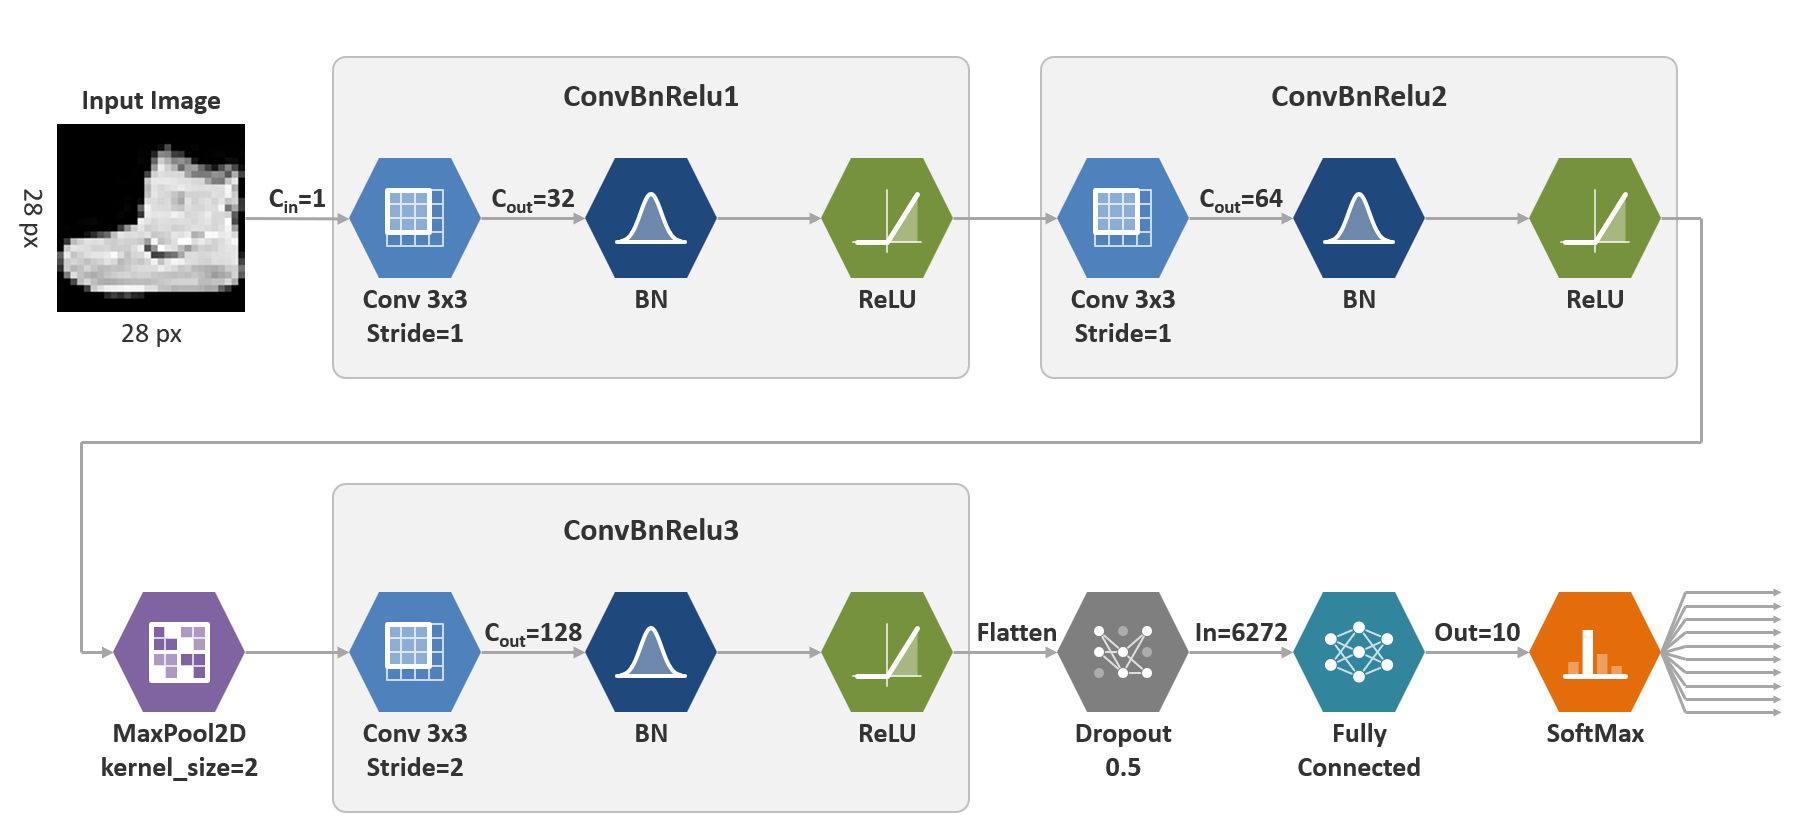

In [ ]:
#@title Dummy input  { form-width: "70%" }
# input_size = (batch_n, img_ch,img_width, img_height)
input_size = (1, 1, 28, 28)  #@param
dummy_input = torch.randn(input_size).to(device)

#### Count network's parameters and MAC operations

---

A useful function to measure the model's MAC operations and number of parameters.

**TorchInfo insights:**
This tool calculates the Parameters Size as (number_of_parameters * 4).
This because each parameter needs 4 Bytes (32bit) to be represented in float32 format.

In [ ]:
def print_summary(net, input_size, verbose=True):
    from torchinfo import summary

    net_info = summary(net, input_size=input_size)
    params = net_info.total_params
    macs = net_info.total_mult_adds

    if verbose: print(net_info)

    return params, macs

# calculate number of parameters and mac operations
params, macs = print_summary(deepcopy(net), input_size)  # use deepcopy to avoid graph modifications by hese function calls

# print them
print("\nNetwork's \tnumber of parameters: %.3fk \tMAC: %.3fM\n" % (params/1e3, macs/1e6))


#### Dataset & DataLoaders

---

We use the [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist), which is a set of 28x28 grayscale images of clothes.

In [ ]:
def get_data_loaders(train_batch_size=128, val_batch_size=128, path='./data/fashionmnist',verbose=False):
    # 1. define data transformations
    fashion_mnist = datasets.FashionMNIST(download=True, train=True, root=path).data.float()
    data_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((fashion_mnist.mean()/255,), (fashion_mnist.std()/255,))])

    # 2. Load train/valid datasets
    train_dataset = datasets.FashionMNIST(download=False, root=path, transform=data_transform, train=True)
    valid_dataset = datasets.FashionMNIST(download=False, root=path, transform=data_transform, train=False)

    # 3. define dataloaders
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=train_batch_size,
        shuffle=True)
    
    valid_loader = torch.utils.data.DataLoader(
        valid_dataset,
        batch_size=val_batch_size,
        shuffle=False)

    # Optional: count how many images we have in each set
    train_dataset_size = len(train_dataset)
    valid_dataset_size = len(valid_dataset)

    if verbose:
        print('Dataset size:\nTraining images %d,\nValidation images %d' % (train_dataset_size, valid_dataset_size))

    return train_loader, valid_loader

train_loader, val_loader = get_data_loaders(verbose=True)


#### Testing the CNN over the dataset

---


##### Accuracy Metric calculation

First we define a function to calculate the accuracy, defined as: `accuracy = num_correct_predictions/total_n_predictions`



In [ ]:
def calculate_accuracy(best_guesses, targets):
    num_correct = torch.eq(targets, best_guesses).sum().item()
    total_guesses = len(targets)
    correct_percentage = num_correct / total_guesses

    return correct_percentage

##### Testing Function
The following cell defines a function, `validate,` that runs a network on a dataset and shows the percentage of the dataset that was correctly classified.

In [ ]:
from brevitas.export.inference import quant_inference_mode

def validate(net, val_loader, loss_function):
    total_loss = 0.
    total_correct = 0.
    total_samples = 0

    # set net to evaluating (testing)
    net.eval()
    with torch.no_grad(), quant_inference_mode(net):
        for data in tqdm(val_loader):
            inputs, labels = data[0].to(device), data[1].to(device)
            batch_size = len(labels)

            # net forward
            outputs = net(inputs) # this gets the prediction from the network

            # calculate loss (weighted by the batch size, as the last batch can be smaller)
            loss = loss_function(outputs, labels)
            total_loss += loss.item() * batch_size

            # calculate validation accuracy
            predicted_classes = torch.max(outputs, 1)[1] # get class from network's prediction
            total_correct += calculate_accuracy(predicted_classes.cpu(), labels.cpu()) * batch_size
            total_samples += batch_size

    average_val_loss = total_loss / total_samples
    average_val_accuracy = total_correct / total_samples

    return average_val_accuracy, average_val_loss


#### Training Loop

In [ ]:
# Move net to the selected device (CPU in this lab):
net.to(device)

# Define loss function
loss_function = nn.CrossEntropyLoss() # cross entropy works well for multi-class problems


def training(net, train_loader, val_loader, loss_function, epochs, lr=3e-4):
    # Define optimizer
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    # Count tot batches
    tot_train_batches = len(train_loader)
    tot_val_batches = len(val_loader)

    # Create lists to store training history
    train_loss_history = []
    train_accuracy_history = []

    # Create lists to store validation history
    val_loss_history = []
    val_accuracy_history = []

    start_ts = time.time()

    # Loop for every epoch (training + evaluation)
    for epoch in range(epochs):
        total_epoch_loss = 0
        train_accuracy = []

        # Progress bar (works in Jupyter notebook too!)
        progress = tqdm(enumerate(train_loader), desc="Loss: ", total=tot_train_batches)

        # ----------------- TRAINING  -------------------- #
        # Set model to training
        net.train()

        for batch_idx, data in progress:
            inputs, labels = data[0].to(device), data[1].to(device)

            # Compute prediction (forward input in the model)
            outputs = net(inputs)

            # Compute prediction error with the loss function
            loss = loss_function(outputs, labels)

            # Backpropagation
            net.zero_grad()
            loss.backward()

            # Optimizer step
            optimizer.step()

            # Getting training quality data
            current_loss = loss.item()

            # Compute average loss
            total_epoch_loss += current_loss
            average_train_loss = total_epoch_loss/(batch_idx+1)

            # Calculate training accuracy
            predicted_classes = torch.max(outputs, 1)[1] # get class from network's prediction
            train_accuracy.append(calculate_accuracy(predicted_classes.cpu(), labels.cpu()))
            average_train_accuracy = sum(train_accuracy)/(batch_idx+1)

            # Updating progress bar
            progress.set_description("Training Loss: {:.4f}, Accuracy: {:.4f}".format(average_train_loss, average_train_accuracy))

        # ----------------- VALIDATION  ----------------- #
        average_val_accuracy, average_val_loss = validate(net, val_loader, loss_function)

        # Compute mean accuracy
        average_train_accuracy = sum(train_accuracy)/tot_train_batches

        # Print training/validation Accuracy and Loss
        print('Epoch %d/%d' % (epoch+1,epochs), 'Training loss:  %.4f' % (average_train_loss), 'Accuracy: %.4f' % (average_train_accuracy))
        print('Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

        # Append current average training loss to a buffer variable, for plotting learning curve later
        train_loss_history.append(average_train_loss)
        val_loss_history.append(average_val_loss)
        train_accuracy_history.append(average_train_accuracy)
        val_accuracy_history.append(average_val_accuracy)

    print('Training time: %.1f seconds' % (time.time()-start_ts))


    return train_loss_history, train_accuracy_history, val_loss_history, val_accuracy_history

# Retrain the network (optional: Task 1 loads pre-trained weights anyway)
run_recap_training = False #@param {type:"boolean"}

if run_recap_training:
    epochs = 2
    _, _, _, _ = training(net, train_loader, val_loader, loss_function, epochs)

#### Save/Load the CNN weights


In [ ]:
#@title Training parameters { form-width: "70%" }
model_export_path = "./model/" #@param {type:"string"}
model_name = 'ExampleNet.pth' #@param {type:"string"}

os.makedirs(model_export_path, exist_ok=True)

In [ ]:
def save_net(net,model_path, model_name):
    # Save Pytorch model
    torch.save(net.state_dict(), join(model_path,model_name))

save_net(net,model_export_path, model_name)

In [ ]:
def load_net(net, model_path, model_name, device):
    ''' Load a PyTorch Model '''
    checkpoint_file= join(model_path,model_name)
    # Load weights file
    state_dict = torch.load(checkpoint_file, map_location=device)

    # Load weights into the network
    net.load_state_dict(state_dict)

    # To device (cpu or gpu)
    net = net.to(device)
    
    return net

**This concludes the recap. Let's now move to the tasks!**

## **Task 1:** Load pre-trained model

---

Now, reload the pre-trained network. If you ran the optional training in the recap, you can use your own weights (saved in `./model/`); otherwise, use the `ExampleNet.pth` we provide. Download it from the lab repository!

In [ ]:
!mkdir -p pretrained
!wget -q -O pretrained/ExampleNet.pth https://github.com/EEESlab/APAI26-LAB03-DNN-Shrinking-and-Quantization/raw/main/ExampleNet.pth

In [ ]:
#@title Define path for CNN's pre-trained weights { form-width: "70%" }
pre_trained_path = "./pretrained" #@param {type:"string"}
model_name = 'ExampleNet.pth' #@param {type:"string"}

### Load pre-trained weights

In [ ]:
load_net("""YOUR CODE HERE""")  # Complete the function!

Test again the network accuracy, to be sure that you saved/loaded weights correctly.



In [ ]:
# Test over validation dataset
loss_function=nn.CrossEntropyLoss()
average_val_accuracy, average_val_loss = validate(net, val_loader, loss_function)

# Print valid statistics
print('Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

**If accuracy is ~0.9, you were successful!**

## **Task 2:** Reduce the network's MAC operations

---

Current network has:
*   Number of parameters: 155.616k
*   MAC: 18.3M

**Task:** Reduce it below 5M MAC, but keeping accuracy similar to the starting one.

---

There are different approaches. The first one is the one needed to complete the lab.
1. Reduce the number of channels of the convolutional layers (half them). **This is the intended approach**

You can explore other two ways:

2. Add or remove layers
3. Adjust the stride of the convolutional layers

### New network with reduced size

In [ ]:
# ConvBnRelu is the same building block defined in the recap above: reuse it!

class CNN_reduced(nn.Module):

    def __init__(self, n_classes=10):
        super(CNN_reduced, self).__init__()
        # YOUR CODE HERE

    def forward(self, x):
        # YOUR CODE HERE
        
        return output

net_reduced = CNN_reduced().to(device)


Let's see how many MAC operations the new network has...

In [ ]:
params, macs = print_summary(
    deepcopy(net_reduced),
    input_size
    )  # use deepcopy to avoid graph modifications by hese function calls

print("\nNetwork's \tnumber of parameters: %.3fk \tMAC: %.3fM\n" % (params/1e3, macs/1e6))

**Check:** your network must stay under the 5M MAC constraint. For reference, halving the number of channels of every layer gives ~4.66M MAC.

## **Task 3:** Retrain the network and verify validation accuracy

You can use the same training loop you implemented in LAB2!




In [ ]:
#@title Training parameters { form-width: "70%" }
epochs = 2 #@param {type:"integer"}
batch_size = 128 #@param {type:"integer"}

In [ ]:
# Build Dataloaders
train_loader, val_loader = get_data_loaders(batch_size, batch_size)

In [ ]:
# Train the network!
(train_loss_history,
train_accuracy_history,
val_loss_history,
val_accuracy_history) = training("""YOUR CODE HERE""", train_loader, val_loader, loss_function, epochs)

## **Task 4:** Quantization

We want to quantize the network from a **float32** representation to an **integer** representation.

As we studied in class, quantization is a technique that allow us to compress the neural network (i.e., reduce its size) and potentially to accelerate the inference time (float operations vs int operations).

First, we'll use a "soft" technique called Post-Training Quantization to quantize our network _without_ retraining it.

**From now on, we work on the shrunk network (`net_reduced`) that you trained in Task 3: shrinking and quantization combine to make the model even smaller.**

### Warm-up: quantizing a tensor by hand

Before using Brevitas, let's quantize a tensor by hand, to see what a quantizer actually does.

With **symmetric, per-tensor, linear** quantization to $N$ bits, each floating-point value $x$ is mapped to an integer $q$:

$$q = \mathrm{clamp}\left(\mathrm{round}\left(\frac{x}{s}\right), -q_{max}, q_{max}\right), \qquad q_{max} = 2^{N-1}-1, \qquad s = \frac{x_{max}}{q_{max}}$$

where $s$ is the **scaling factor** and $x_{max}$ is the largest value we want to represent (the *clipping range*). Multiplying back, $\hat{x} = s \cdot q$, gives the *dequantized* value, and the difference $x - \hat{x}$ is the **quantization error**. This is exactly what a fake-quantization node computes in the forward pass.

**TASK:** complete `quantize_symmetric`, computing the scaling factor `scale` and the integer values `q` (**Tip**: use [`torch.round`](https://docs.pytorch.org/docs/stable/generated/torch.round.html) and [`torch.clamp`](https://docs.pytorch.org/docs/stable/generated/torch.clamp.html)).

In [ ]:
def quantize_symmetric(x, bit_width, x_max=None):
    q_max = 2 ** (bit_width - 1) - 1

    if x_max is None:
        x_max = x.abs().max()  # by default, use the full range of x

    scale = """YOUR CODE HERE"""
    q = """YOUR CODE HERE"""

    return q, scale

# Pick the largest convolution of the shrunk network
convs = [m for m in net_reduced.modules() if isinstance(m, nn.Conv2d)]
w = max(convs, key=lambda m: m.weight.numel()).weight.detach().cpu().flatten()

for bit_width in (8, 4, 2):
    q, scale = quantize_symmetric(w, bit_width)
    w_hat = q * scale  # dequantize
    error = (w - w_hat).abs()
    
    print('%db: scale=%.5f, levels used=%3d, mean |error|=%.5f, max |error|=%.5f (scale/2=%.5f)' % (
        bit_width, scale, q.unique().numel(), error.mean(), error.max(), scale / 2))

Let's visualize what 4-bit quantization does to the weights: on the left, the weight distribution with the 15 values that 4 bits can represent; on the right, how each weight is mapped to one of them.

In [ ]:
q, scale = quantize_symmetric(w, 4)
w_hat = q * scale

fig, (ax_hist, ax_map) = plt.subplots(1, 2, figsize=(12, 4))

ax_hist.hist(w.numpy(), bins=200)
for level in torch.unique(w_hat):
    ax_hist.axvline(level, color='red', alpha=0.3)  # representable values
ax_hist.set_title('Weight distribution and 4b quantization levels (red)')
ax_hist.set_xlabel('Weight value')

w_sorted = w.sort().values
w_hat_sorted = w_hat[w.argsort()]
ax_map.plot(w_sorted.numpy(), w_sorted.numpy(), label='Original')
ax_map.plot(w_sorted.numpy(), w_hat_sorted.numpy(), label='Quantized (4b)')
ax_map.set_title('Original vs. quantized weights')
ax_map.set_xlabel('Original value')
ax_map.set_ylabel('Value after quantization')
ax_map.legend()

plt.tight_layout()
plt.show()

Most weights are concentrated around zero, while the range (and therefore the scaling factor) is set by a few large outliers. Let's see what happens if we **clip** the range at a percentile of $|w|$ instead of using its maximum: the outliers are clipped, but all other weights are represented more finely. This is the same trade-off that Brevitas makes when it calibrates the activation range with a percentile.

In [ ]:
bit_width = 4
for percentile in (100, 99.9, 99, 95):
    x_max = torch.quantile(w.abs(), percentile / 100)
    q, scale = quantize_symmetric(w, bit_width, x_max)
    mse = ((w - q * scale) ** 2).mean()
    print('%db, clipping at the %5.1f%% percentile: x_max=%.4f, MSE=%.2e' % (bit_width, percentile, x_max, mse))

---
**Questions:**
* Which clipping range gives the lowest error at 4 bits? What happens if you clip too much?
* Try again at 8 bits: does clipping still help? Why?

---

We will use the open-source [**Brevitas**](https://github.com/Xilinx/brevitas) tool, developed by AMD Xilinx, as our main quantization framework. Resources:
 * https://xilinx.github.io/brevitas/

* The computational graph of our network uses floating-point operands, i.e., it is a floating-point computational graph.

* Similarly to other quantization tools, the first step of Brevitas' operation is to replace the nodes in the graph with ones that support quantization, i.e., explicitly include weight and (potentially) activation quantization in their `forward` methods.

* Quantization-aware nodes also make it possible to collect statistics on the weight and activation distribution, which in turn are used to improve the quantization itself by selecting the correct quantization range.

* This information will be transformed into a set of floating-point zero-offsets and scaling factors applied to integer weights and activations.

* The conversion from a "pure" model to one that is quantization-aware is called the fake quantization, and it produces a **Fake-Quantized (FQ)** model: specifically the FQ step introduces linear quantizers into the computational graph, but at the same time continues to operate with floating-point operands.

* In Brevitas, fake quantization can be performed *layer-wise*, i.e., by manually replacing one `torch.nn.Module` at a time with its quantization-aware counterpart, or *graph-based*, i.e., automatically, starting from a `torch.fx` trace of the network.

* In this tutorial, we'll rely on the graph-based strategy: Brevitas traces the network and replaces the nodes for us, following a set of maps that we provide, so it automates most of the work.

* The FQ graph is where we apply all transformation that still require complete trainability and, as a consequence, rely on float representation.

* However, the FQ graph cannot be directly deployed: scaling factors are applied in floating-point, which we generally want to avoid; some operations that integer hardware needs (e.g., requantizing the 32b accumulator of each layer back to 8b) are not explicitly represented; and in general it is not a bit-true representation of any full-integer operation that will happen in deployment.

* Brevitas alone does not give us a bit-true integer graph: we'll use a separate tool, **DeepQuant**, to perform a second-stage *fake-to-true* transformation and get a fully integer graph.

### **1st quantization step: Float-to-fake**

This is the first step for preparing & converting a conventional neural network to the quantized form, which is where “fake quantization” nodes come in (image below: red nodes):

* The role that fake quantization nodes fulfill is to simulate the rounding effect of quantization in the forward pass, as it would occur in actual inference of a quantized network. So we are not converting activation's output
and the convolutional weights to fixed-point representation (`integer`), we are just adding a "fake quantization" node that simulates the effect of quantization. This allows to keep all parameters stored as float with the real full-precision.

***Why do we want to keep the original `float32` values?***

* It is needed at training time, so that backpropagation still works as usual. Gradient updates are tiny: if we stored only the quantized values, most updates would be rounded away and the network could not learn. Keeping the full-precision `float32` weights lets these small updates accumulate.

***Why do we want to train a quantized network then ?***

* Frequently, after applying quantization, we must run a few epochs of fine-tuning (called **quantization-aware training**) to adjust for the precision loss introduced by a lower bitwidth.
* The alternative, which we'll follow in the first part of this tutorial, is to apply **post-training quantization**, which relies on statistics collection and calibration to adapt the ranges and scaling factors of quantizers.

**Summary:** Fake quantization nodes simulate the quantization effects on weights and output activations during the forward pass (`input->output`), while all parameters keep their original `float32` values. During backpropagation (`input<-output`), rounding is a problem, since its gradient is zero almost everywhere. It is therefore approximated with the **Straight-Through Estimator (STE)**: the gradient passes through the rounding as if it were the identity function. Values that fall outside the quantization range and get clipped, instead, receive a zero gradient.


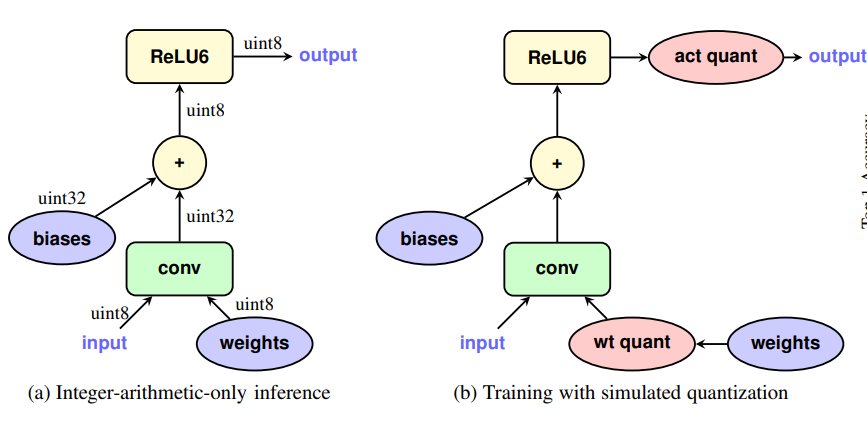

To perform F2F conversion, we must replace standard PyTorch Modules with corresponding FakeQuantized counterparts.
With Brevitas, we start by taking a "deep copy" of our shrunk floating-point net, `net_reduced` (to keep it untouched), then we operate on the copy.

Our first step is to perform *activation equalization*, a technique based on [**SmoothQuant**](https://arxiv.org/abs/2211.10438) used to smooth out any outliers in the activation distribution by migrating their "quantization difficulty" towards weights.
This is directly supported in Brevitas and can be run to our copied network as a preliminary step.
Afterwards, we run one validation round to double-check functionality.

In [ ]:
def add_zero_biases(net):
    # Add a zero bias to every conv/linear layer that has none
    for layer in net.modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)) and layer.bias is None:
            layer.bias = torch.nn.Parameter(torch.zeros(layer.weight.size()[0], device=layer.weight.device))

# DeepCopy of the shrunk net
net_copy = deepcopy(net_reduced)
add_zero_biases(net_copy)

In [ ]:
from brevitas.graph.equalize import activation_equalization_mode

def equalize_activations(net, cal_loader, alpha=0.5):

    # set net to evaluating (testing)
    net.eval()
    with activation_equalization_mode(net, alpha):
      with torch.no_grad():
          for batch_idx, data in enumerate(cal_loader):
              inputs, _ = data[0].to(device), data[1].to(device)

              # net forward
              _ = net(inputs) # this gets the prediction from the network

# use validation set for activation equalization
calib_loader = val_loader
equalize_activations(net_copy, calib_loader)

average_val_accuracy, average_val_loss = validate(net_copy, val_loader, loss_function)

# Print valid statistics
print('Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

We expect the accuracy to be virtually unchanged compared to before equalization.

After equalization, we fake-quantize the network using Brevitas' graph-based (`torch.fx`) API, in two steps:
1. `preprocess_for_quantize` traces the network with `torch.fx` into a graph model and applies some standard transformations, such as merging each BatchNorm into the preceding convolution. It does not quantize anything yet, so the accuracy should still be unchanged.
2. `quantize` walks the traced graph and replaces each floating-point node with its quantization-aware counterpart, following three maps that we provide:
   * `compute_layer_map`: how to replace compute layers (`nn.Conv2d` → `qnn.QuantConv2d`, `nn.Linear` → `qnn.QuantLinear`, ...);
   * `quant_act_map`: how to replace activations (`nn.ReLU` → `qnn.QuantReLU`);
   * `quant_identity_map`: which `qnn.QuantIdentity` nodes to insert to quantize tensors that do not come from a quantized layer, e.g., the network input.

Each entry of `compute_layer_map` is a quantized layer class plus the keyword arguments used to build it:
 * `weight_quant`, `input_quant`, `output_quant`, `bias_quant`: the *quantizer* applied to the layer's weights, input, output and bias.
 * `weight_bit_width`, `output_bit_width`: the bit width of the weights and of the output.
 * `return_quant_tensor=True`: the layer returns a `QuantTensor`, which carries the scale factor and zero point together with the values, so that the next layer knows how its input was quantized.

Brevitas quantizer names describe what they do. For example, `Int8WeightPerTensorFloat` is signed 8-bit (`Int8`, vs. unsigned `Uint8`), meant for weights (`Weight`, vs. `Act` for activations), uses a single scaling factor for the whole tensor (`PerTensor`, vs. per-channel), and that scaling factor is a floating-point number (`Float`).

Here we make the following choices:
 * **weights**: 8b, signed and symmetric, with `per_tensor` granularity, i.e., one single scaling factor (and a related range from `wmin` to `wmax`) is used for all the weights of a layer.
 * **layer inputs and outputs**: 8b, signed. Their range is set during calibration from activation statistics: by default, Brevitas keeps activations up to the 99.999% percentile within the representable range. Reducing the range might make it easier to quantize, but will result in gross precision loss on activation outliers.
 * **biases**: 32b, since in the integer network they are added to the 32b accumulator of the MAC operations.
 * **scaling factors**: floating-point (`Float`), which means that quantization is free to use any scaling factor. Conversely, we could also set up quantization to use only power-of-two scaling factors: this makes it possible to reduce all normalization to simple shifts (practically a regular fixed-point representation), at the price of losing flexibility, and thus accuracy.

In the next cell we run step 1 and check the accuracy again; then you will complete the maps for step 2.

In [ ]:
from brevitas.graph.quantize import preprocess_for_quantize
gnet = preprocess_for_quantize(net_copy)

average_val_accuracy, average_val_loss = validate(gnet, val_loader, loss_function)

# Print valid statistics
print('Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

----
**TASK ASSIGNMENT**

Complete the Layer Map following the choices stated before.

**Tip**: All classes you need are imported (you do not need the documentation).

In [ ]:
from brevitas.graph.quantize import quantize
from brevitas.quant import (
  Int8ActPerTensorFloat,
  Int8WeightPerTensorFloat,
  Int32Bias,
  Uint8ActPerTensorFloat,
)

computeLayerMap = {
  nn.Conv2d: (
    qnn.QuantConv2d,
    {
      "input_quant": """YOUR CODE HERE""",
      "weight_quant": """YOUR CODE HERE""",
      "output_quant": """YOUR CODE HERE""",
      "bias_quant": """YOUR CODE HERE""",
      "bias": True,
      "return_quant_tensor": True,
      "output_bit_width": """YOUR CODE HERE""",
      "weight_bit_width": """YOUR CODE HERE""",
    },
  ),

  nn.Linear: (
    qnn.QuantLinear,
    {
      "input_quant": """YOUR CODE HERE""",
      "weight_quant": """YOUR CODE HERE""",
      "output_quant": """YOUR CODE HERE""",
      "bias_quant": """YOUR CODE HERE""",
      "bias": True,
      "return_quant_tensor": True,
      "output_bit_width": """YOUR CODE HERE""",
      "weight_bit_width": """YOUR CODE HERE""",
    },
  ),

  nn.BatchNorm2d: (
    qnn.BatchNorm2dToQuantScaleBias,
    {
      'weight_quant': """YOUR CODE HERE""",
      'bias_quant': """YOUR CODE HERE""",
      'return_quant_tensor': True
    }
  ),
}

quantActMap = {
  nn.ReLU: (
    qnn.QuantReLU,
    {
      "act_quant": Uint8ActPerTensorFloat,
      "return_quant_tensor": True,
      "bit_width": 8,
    },
  ),
}

quantIdentityMap = {
  "signed": (
    qnn.QuantIdentity,
    {
      "act_quant": Int8ActPerTensorFloat,
      "return_quant_tensor": True,
      "bit_width": 8,
    },
  ),

  "unsigned": (
    qnn.QuantIdentity,
    {
      "act_quant": Uint8ActPerTensorFloat,
      "return_quant_tensor": True,
      "bit_width": 8,
    },
  ),
}

qnet = quantize(
  graph_model=gnet,
  compute_layer_map=computeLayerMap,
  quant_act_map=quantActMap,
  quant_identity_map=quantIdentityMap,
)

# Test over validation dataset
loss_function=nn.CrossEntropyLoss()

average_val_accuracy, average_val_loss = validate(qnet, val_loader, loss_function)

# Print valid statistics
print('Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

Did you notice the accuracy drop? We should do something about it!

But first, let us check the topology of the network.

In [ ]:
# List the quantization-aware modules that Brevitas inserted into the graph
for name, m in qnet.named_modules():
    if isinstance(m, (qnn.QuantConv2d, qnn.QuantLinear, qnn.QuantReLU, qnn.QuantIdentity)):
        print(f"{name:30s} {type(m).__name__}")

To fix network accuracy, we need to initialize correctly the minima and maxima of activations, which is used to correctly represent them in the latter operations. This step is typically called calibration and, in PTQ, it is the only typically necessary step to achieve good performance. We expect no accuracy loss compared to the floating-point network after calibration.

In [ ]:
from brevitas_examples.imagenet_classification.ptq.ptq_common import calibrate

# use validation set for calibration
calib_loader = val_loader

# initializes wmax,wmin, amax, amin
calibrate(calib_loader, qnet)

# Test over validation dataset
loss_function=nn.CrossEntropyLoss()

average_val_accuracy, average_val_loss = validate(qnet, val_loader, loss_function)

# Print valid statistics
print('Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

At this stage, the FQ of the network is complete: at 8 bits, it should be as accurate as the floating-point network. What happens if we go lower?

To quickly build fake-quantized networks with different settings, we wrap all the steps above (copy, bias workaround, equalization, preprocessing, quantization with your maps, calibration) in a single function, `build_qnet`. To keep it fast, equalization and calibration use a small subset of the **training** set. This is also good practice: calibrating on the same data we evaluate on makes the results look better than they are.

In [ ]:
from torch.utils.data import Subset, DataLoader

# Small calibration set: 1024 training images
calib_subset_loader = DataLoader(Subset(train_loader.dataset, range(1024)), batch_size=128, shuffle=False)

def build_qnet(float_net, bit_width=8, equalize=True, calib_loader=calib_subset_loader):
    ''' Fake-quantize float_net with weights and activations at bit_width bits, using the maps defined above '''
    net_copy = deepcopy(float_net)
    add_zero_biases(net_copy)
    if equalize:
        equalize_activations(net_copy, calib_loader)
    gnet = preprocess_for_quantize(net_copy)

    # Same maps as before, with the bit width overridden
    layer_map, act_map, identity_map = deepcopy(computeLayerMap), deepcopy(quantActMap), deepcopy(quantIdentityMap)
    for _, kwargs in layer_map.values():
        for key in ('weight_bit_width', 'output_bit_width'):
            if key in kwargs:
                kwargs[key] = bit_width
    for _, kwargs in list(act_map.values()) + list(identity_map.values()):
        kwargs['bit_width'] = bit_width

    qnet_b = quantize(
        graph_model=gnet,
        compute_layer_map=layer_map,
        quant_act_map=act_map,
        quant_identity_map=identity_map,
    )
    calibrate(calib_loader, qnet_b)

    return qnet_b

### **2nd quantization step: Quantization-aware training (QAT)**

After applying quantization, we can run a few epochs (just 1 is enough in this case) of fine-tuning, called *Quantization-Aware Training (QAT)*, to adjust for the precision loss introduced by a lower bitwidth.

This is particularly useful if we target very low bitwidth networks. At 8 bits, PTQ is already as accurate as the floating-point network, so QAT has little to recover. To see it pay off, let's go down to **3 bits**: first with PTQ only (feel free to try 4 bits too: how much accuracy you lose depends on your network).

In [ ]:
# PTQ at 3 bits
qnet_3b = build_qnet(net_reduced, bit_width=3)

average_val_accuracy, average_val_loss = validate(qnet_3b, val_loader, loss_function)
print('3b PTQ - Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

The accuracy drops noticeably compared to 8 bits. Let's try to recover it with QAT.

In [ ]:
#@title Number of quantization-aware training (QAT) epochs { form-width: "70%" }
n_QAT_epochs = 1 #@param {type:"integer"}

Start quantization-aware fine-tuning of the 3-bit network `qnet_3b`!

In [ ]:
# Train the network!
(train_loss_history,
train_accuracy_history,
val_loss_history,
val_accuracy_history) = training(
    """YOUR_NETWORK_HERE""",
    train_loader,
    val_loader,
    loss_function,
    n_QAT_epochs,
    lr=1e-4)

In [ ]:
# We don't re-run calibration here: during QAT, the activation scaling factors
# are trained together with the weights, and re-calibrating could overwrite them.

# Test over validation dataset
average_val_accuracy, average_val_loss = validate(qnet_3b, val_loader, loss_function)

# Print valid statistics
print('3b QAT - Validation Loss: %.4f' % (average_val_loss), 'Accuracy: %.4f' % (average_val_accuracy))

### Exploration: how low can we go?

Let's now sweep the bit width systematically, comparing:
* PTQ without activation equalization;
* PTQ with activation equalization;
* PTQ with activation equalization, followed by one epoch of QAT. To keep it fast, QAT here uses a subset of 10k training images.

The full sweep takes a while: set `include_qat = False` to skip the QAT runs.

In [ ]:
#@title Bit-width sweep { form-width: "70%" }
bit_widths = [8, 6, 4, 3, 2] #@param
include_qat = True #@param {type:"boolean"}

qat_subset_loader = DataLoader(Subset(train_loader.dataset, range(10000)), batch_size=128, shuffle=True)

results = {'PTQ (no equalization)': [], 'PTQ': [], 'PTQ + QAT': []}
for bit_width in bit_widths:
    print('\n===== %d bits =====' % bit_width)
    qnet_sweep = build_qnet(net_reduced, bit_width, equalize=False)
    results['PTQ (no equalization)'].append(validate(qnet_sweep, val_loader, loss_function)[0])

    qnet_sweep = build_qnet(net_reduced, bit_width, equalize=True)
    results['PTQ'].append(validate(qnet_sweep, val_loader, loss_function)[0])

    if include_qat:
        _, _, _, qat_val_accuracy = training(qnet_sweep, qat_subset_loader, val_loader, loss_function, 1, lr=1e-4)
        results['PTQ + QAT'].append(qat_val_accuracy[-1])

In [ ]:
float_accuracy, _ = validate(net_reduced, val_loader, loss_function)

plt.figure(figsize=(7, 4))
for label, accuracies in results.items():
    if accuracies:
        plt.plot(bit_widths, accuracies, marker='o', label=label)
plt.axhline(float_accuracy, color='gray', linestyle='--', label='float32')
plt.xlabel('Bit width (weights and activations)')
plt.ylabel('Validation accuracy')
plt.gca().invert_xaxis()
plt.grid(alpha=0.3)
plt.legend()
plt.show()

---
**Questions:**
* At which bit width does PTQ start losing accuracy?
* How much does activation equalization help, and at which bit widths?
* How much accuracy can QAT recover?
* Run the sweep on the original network too (replace `net_reduced` with `net`): which network is more robust to quantization? Why?
* At 8 bits, PTQ + QAT may end up *above* the float32 line. Why? (**Tip**: how many epochs did we train the float32 network for?)

---

### **3rd quantization step: Fake-to-true**

At this stage, we drop the "fake-quantization nodes" (the red nodes in the figure) and we transform all parameters to a fully integer representation, dropping the original `float32` values.
For doing so, we must freeze the `min` and `max` range and the scaling factor for the input, also called *quantum*. This process is called **True Quantization (TQ)**.

We deploy the 8-bit network `qnet`, which we fake-quantized with PTQ above.

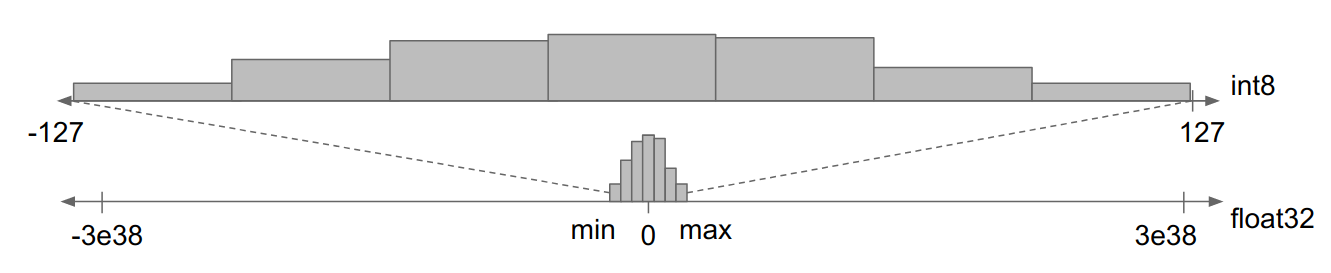

We perform this transformation using **DeepQuant**, a PULP platform tool that is specialized in transforming the FQ output of Brevitas and bringing it to TQ.
DeepQuant operates in a nearly automatic way.

It can happen that you get an error at this stage: **don't panic** and rerun the cell. DeepQuant is designed to stop if outputs are not consistent, meaning the step has changed the output significantly.

In [ ]:
#@title fake-to-true (F2T) function {form-width: "30%"}

try:
    from DeepQuant import brevitasToTrueQuant
except ImportError:  # the cloned DeepQuant/ folder can shadow the installed package
    from DeepQuant.DeepQuant import brevitasToTrueQuant

sampleInput = torch.randn(1, 1, 28, 28)
tqnet = brevitasToTrueQuant(qnet, sampleInput, exportPath="./DeepQuantTest", debug=True)

A sanity check: we compare the predictions of the fully-integerised program with the ground truth to verify that they are coherent.


In [ ]:
#@title Sanity check {form-width: "30%"}
import random
random_idx = random.randrange(0, len(val_loader.dataset))

# Pick random image from dataset
x, y_gt_int = val_loader.dataset.__getitem__(random_idx)
x = x.unsqueeze(0)
net_reduced.to('cpu')

# Prediction float32 (shrunk) network
y_pr_float = net_reduced(x)
y_pr_float_max = y_pr_float.argmax(axis=1)

x, y_gt_int = val_loader.dataset.__getitem__(random_idx)
x = x.unsqueeze(0)

# Prediction quantized network
y_pr = tqnet(x)
y_pr_int = y_pr.argmax(axis=1)

print("True Quantized: \t\tTrue: {} - Predicted: {}".format(int(y_gt_int), y_pr_int.item()))
print("FLOAT32:\tTrue: {} - Predicted: {}\n".format(int(y_gt_int), y_pr_float_max.item()))

Let's verify that the accuracy didn't drop between FLOAT32 and TrueQuantized stages.

In [ ]:
# Test the NON QUANTIZED network over validation dataset
average_val_accuracy, average_val_loss = validate(
    """YOUR_NETWORK_HERE""",
    val_loader,
    loss_function)

# Print valid statistics
print('FLOAT32 Validation Accuracy: %.4f' % (average_val_accuracy))

In [ ]:
# Test the QUANTIZED network over validation dataset
average_val_accuracy, average_val_loss = validate(
    """YOUR_NETWORK_HERE""",
    val_loader,
    loss_function)

# Print valid statistics
print('INT Validation Accuracy: %.4f' % (average_val_accuracy))

## **Task 5:** Export to ONNX format


The trained networks can be exported in [**ONNX (*Open Neural Network eXchange*)**](https://github.com/onnx/onnx) format for deployment. ONNX is an open standard, widely supported by deep learning frameworks and deployment tools for exchanging trained networks. It stores all the necessary elements to reload a network:
* topology: number of layers, how they are linked and their type;
* layer structure: stride, filter dimension, channels, etc..
* parameters: for each layer, all the weights and numeric parameters are stored.

**How to use:** To see how the model looks like, the following cells will
trigger a download of the ONNX file to your local machine. Then open [Netron](https://netron.app), a tool to visualize neural networks, **in a new browser tab**, and drag and drop the ONNX file on top of it!


**IMPORTANT:** now we are going to visualize two networks: 1. the original float32 network (so, the non-quantized one), and 2. the quantized one.


#### **1. Export the original Float32 model (non-quantized!)**

Export the ONNX file of the NON-quantized network.


In [ ]:
net_reduced.eval()
torch.onnx.export("""YOUR_NETWORK_HERE""", dummy_input, 'ExampleNet_Float32.onnx')

Download the ONNX file on your local computer

In [ ]:
from google.colab import files
files.download('ExampleNet_Float32.onnx')

Open [Netron](https://netron.app) in a new browser tab and visualize the non-quantized network, `ExampleNet_Float32.onnx`.
That is, accept cookies, and "Open Model..." or drag and drop the file you downloaded.

---
**ASSIGNMENT TASK:**

**Edit this cell to add your answers!**

Use Netron to analyze the ONNX file of the original NON QUANTIZED network and answer the following question:

* What's the data format of the convolutional layers' weights?
* Is the decimal part of the convolutional weights !=0 ?  **Paste here the value of a single weight as an example**.
* What's the kernel size of all the convolutions?

---

***Hints:***
- Examples of possible data formats: `int8`, `int16`, `int32`, `int64`, `float16`, `float32`
- The decimal part of `1234.567` is `0.567`

### **2. Study the Quantized model**

Download the quantized network, `DeepQuantTest/network.onnx`, and open it in [Netron](https://netron.app) in a new browser tab, as before.


In [ ]:
from google.colab import files
files.download('DeepQuantTest/network.onnx')

---
**ASSIGNMENT TASK:**

**Edit this cell to add your answers!**

Use Netron to analyze the ONNX file of the QUANTIZED network and answer the following question:

* What's the size of the input image?
* What's the data format of all the convolutional weights?
* Is the decimal part of the convolutional weights !=0? **Tip**: You cannot see the values of weights, differently from the other ONNX file. Reason on the sequence of operations.
* What's the kernel size of all the convolutions?
* What's the quantization bitwidth of the convolutional weights? **Tip**: look at the min/max values on the clip operation!

---